In [1]:
import scipy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn

In [23]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

if os.getcwd().split('/')[-1] == 'genjoin':
    os.chdir('../../')
os.getcwd()

'/home/pavel/Downloads/ZHAW/GraphQueryML'

# Why do we choose to have 3 samples of runtime for each query/method?

From our previous article, it's clear that starting from 3rd execution in a row we can trust the runtime as an unbiased estimation of the true runtime. However, as long as we need to answer a question like "Is Postgres running faster than GenJoin", we need to have 2 samples from Postgres and GenJoin. As long as we do not have predefined minimal detectable effect and desired statistical power, we choose the number of samples arbitrary, aiming to have a stable variance with the minimal of executions-per-query required. Experimentally studying samples from standard normal distributions of different sizes and applying elbow rule, we conclude that after n=3 the variance changes not significantly.

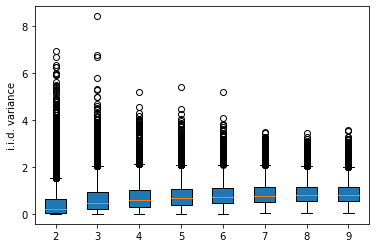

In [22]:
np.random.seed(1234)

variances = []
counter = 0
for size in range(2, 10):
    variances.append([])
    for _ in range(10_000):
        variances[counter].append(np.var(scipy.stats.norm.rvs(size=size)))
    counter += 1

labels = range(2, 10)

fig, ax = plt.subplots()
ax.set_ylabel('Variance of i.i.d. variable')

bplot = ax.boxplot(variances,
                   patch_artist=True,  # fill with color
                   labels=labels)  # will be used to label x-ticks
plt.show()

# Why we do not run a chain-of-plans to improve the model output quality?

Experimentally though 25 shots of chain-of-plans we show that standard deviation of total execution time stays stable through the procedure, i.e. perhaps to make chain-of-plans work, we need to train a chain model with specific stopping criteria (like accuracy of p-value prediction)

In [24]:
data = pd.read_csv('./data/processed/JOB/JOB/ablation_chain_test.csv')

In [51]:
x = data[data.method == 'cVAE'].groupby(['experiment', 'query_ident', 'shot'], dropna=False)
new_data = x.agg({'execution_time': ['mean']}).reset_index()

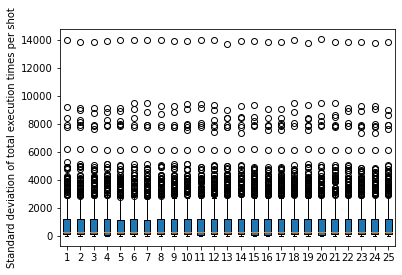

In [69]:
np.random.seed(1234)

labels = range(1, 26)

values = []
for shot in labels:
    values.append(new_data[new_data.shot == shot][('execution_time', 'mean')].values)

fig, ax = plt.subplots()
ax.set_ylabel('Standard deviation of total execution times per shot')

bplot = ax.boxplot(values,
                   patch_artist=True,  # fill with color
                   labels=labels)  # will be used to label x-ticks
plt.show()

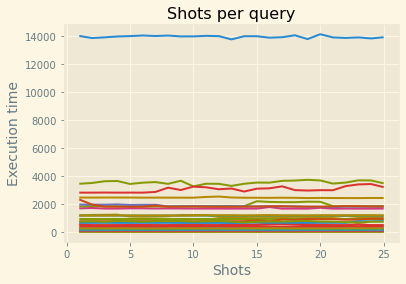

In [75]:
x = range(1, 26)
experiment = 'base_query_split_a'
with plt.style.context('Solarize_Light2'):
    for query_ident in new_data[(new_data.experiment == experiment)].query_ident.unique():
        exec_time = new_data[(new_data.experiment == experiment)&(new_data.query_ident == query_ident)][('execution_time', 'mean')].values
        plt.plot(x, exec_time)
    # Number of accent colors in the color scheme
    plt.title('Shots per query')
    plt.xlabel('Shots', fontsize=14)
    plt.ylabel('Execution time', fontsize=14)

plt.show()